# Orange Inc. customer analytics

**BM04BIM Big Data Management and Analytics, 2026-27, Assignment 1**

Orange Inc. merged its customer, product purchase and transaction databases into one dataset (`orange_inc.csv`).
This notebook cleans the merged data, answers the descriptive questions (Q1-Q10) and the managerial questions (Q11-Q12).
Run it top to bottom on a fresh kernel.

## Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PRODUCT_COLUMNS = ["oPhone", "oWatch", "oPods", "oTV"]
TIER_ORDER = ["silver", "gold", "platinum"]
AGE_ORDER = ["18-25", "25-34", "34-50", ">50"]

NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent
REPO_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "orange_inc.csv"

# In the repo the CSV lives in data/raw; as a standalone submission it sits next to the notebook
if REPO_DATA_PATH.exists():
    OUTPUT_ROOT = PROJECT_ROOT
    DATA_PATH = REPO_DATA_PATH
else:
    OUTPUT_ROOT = NOTEBOOK_DIR
    DATA_PATH = NOTEBOOK_DIR / "orange_inc.csv"

IMAGES_DIR = OUTPUT_ROOT / "Images"
IMAGES_DIR.mkdir(exist_ok=True)
print(f"Reading data from: {DATA_PATH}")

Reading data from: C:\Users\miche\University\Material\Data Science\3_Erasmus\Big Data Management & Analytics\04_Projects\First Assignment\data\raw\orange_inc.csv


## Descriptive analytics

### Q1. Import the data and count missing values

The dataset marks missing cells with `"-"`, so this string is read as missing.

In [2]:
orange_data = pd.read_csv(DATA_PATH, na_values="-", parse_dates=["date"])
print(f"orange_data: {orange_data.shape[0]} rows, {orange_data.shape[1]} columns")

missing_counts = orange_data.isna().sum()
missing_counts = missing_counts.rename_axis("attribute")
missing_table = missing_counts.to_frame(name="missing_values")
missing_table

orange_data: 20000 rows, 10 columns


,missing_values
attribute,
user_id,0
age_bracket,53
tier,28
gender,152
oPhone,50
oWatch,40
oPods,45
oTV,30
date,17


### Q2. Remove rows with missing values

In [3]:
orange_data_clean = orange_data.dropna()
orange_data_clean = orange_data_clean.reset_index(drop=True)
# Product flags were read as float because of the missing cells; restore them to 0/1 integers
orange_data_clean[PRODUCT_COLUMNS] = orange_data_clean[PRODUCT_COLUMNS].astype(int)

rows_removed = len(orange_data) - len(orange_data_clean)
print(f"Rows removed: {rows_removed}")
print(f"Observations in orange_data_clean: {len(orange_data_clean)}")

Rows removed: 428
Observations in orange_data_clean: 19572


All questions below use `orange_data_clean`.

### Q3. Customers who purchased multiple products

In [4]:
orange_data_clean["number_of_products"] = orange_data_clean[PRODUCT_COLUMNS].sum(axis=1)
has_two_or_more = orange_data_clean["number_of_products"] >= 2
orange_data_clean["purchased_multiple_products"] = has_two_or_more.astype(int)

multiple_product_customers = orange_data_clean["purchased_multiple_products"].sum()
print(f"Customers who purchased multiple products: {multiple_product_customers}")

Customers who purchased multiple products: 12154


### Q4. Female customers aged 18-25 who paid with a Visa or Mastercard credit card

In [5]:
is_female = orange_data_clean["gender"] == "female"
is_18_to_25 = orange_data_clean["age_bracket"] == "18-25"
paid_visa_or_mastercard_credit = orange_data_clean["card"].isin(["Visa_credit", "Mastercard_credit"])

young_female_credit_count = (is_female & is_18_to_25 & paid_visa_or_mastercard_credit).sum()
print(f"Female customers aged 18-25 paying with Visa or Mastercard credit: {young_female_credit_count}")

Female customers aged 18-25 paying with Visa or Mastercard credit: 1916


### Q5. Customers outside 18-25, paying by debit card, with two or more products

Debit cards are `Visa_debit`, `Mastercard_debit` and `Other_debit`. The percentage is taken over all customers in `orange_data_clean`.

In [6]:
paid_with_debit = orange_data_clean["card"].str.endswith("_debit")
bought_multiple = orange_data_clean["purchased_multiple_products"] == 1
older_debit_multiple = ~is_18_to_25 & paid_with_debit & bought_multiple

older_debit_multiple_count = older_debit_multiple.sum()
older_debit_multiple_percentage = older_debit_multiple.mean() * 100
print(f"Matching customers: {older_debit_multiple_count} of {len(orange_data_clean)}")
print(f"Percentage: {older_debit_multiple_percentage:.2f}%")

Matching customers: 3733 of 19572
Percentage: 19.07%


### Q6. Customers who purchased all four products

In [7]:
all_four_products_count = (orange_data_clean["number_of_products"] == 4).sum()
print(f"Customers who purchased all four products: {all_four_products_count}")

Customers who purchased all four products: 364


### Q7. Average number of products per loyalty tier

In [8]:
average_products_by_tier = orange_data_clean.groupby("tier")["number_of_products"].mean()
average_products_by_tier = average_products_by_tier.reindex(TIER_ORDER)
average_products_table = average_products_by_tier.round(3).to_frame(name="average_products")
average_products_table

,average_products
tier,
silver,1.757
gold,1.982
platinum,2.162


### Q8a. Sales revenue per customer and total revenue

In [9]:
product_prices = pd.Series({"oPhone": 1300, "oWatch": 350, "oPods": 250, "oTV": 2600})

orange_data_clean["sales_revenue"] = orange_data_clean[PRODUCT_COLUMNS].dot(product_prices)
total_revenue = orange_data_clean["sales_revenue"].sum()
print(f"Total sales revenue: €{total_revenue:,.0f}")

Total sales revenue: €33,377,850


### Q8b. Month with the highest sales revenue

In [10]:
orange_data_clean["month_of_purchase"] = orange_data_clean["date"].dt.month

revenue_by_month = orange_data_clean.groupby("month_of_purchase")["sales_revenue"].sum()
revenue_by_month = revenue_by_month.reindex(range(1, 13), fill_value=0)
month_names = [pd.Timestamp(2023, month, 1).strftime("%B") for month in revenue_by_month.index]

best_month = revenue_by_month.idxmax()
best_month_name = month_names[best_month - 1]
print(f"Highest revenue month: {best_month_name} (month {best_month}), €{revenue_by_month.max():,.0f}")

revenue_by_month_table = pd.DataFrame({"month": month_names, "sales_revenue_eur": revenue_by_month.values}, index=revenue_by_month.index)
revenue_by_month_table

Highest revenue month: December (month 12), €5,180,000


,month,sales_revenue_eur
month_of_purchase,,
1,January,2255650
2,February,2150450
3,March,2251850
4,April,2104500
5,May,2281600
6,June,2262600
7,July,2355600
8,August,2168500
9,September,3684900


### Q8c. Total sales revenue per product

In [11]:
units_sold = orange_data_clean[PRODUCT_COLUMNS].sum()
revenue_by_product = units_sold * product_prices
# Revenue split by product must add up to the customer-level total from Q8a
assert revenue_by_product.sum() == total_revenue

product_revenue_table = pd.DataFrame({"units_sold": units_sold, "price_eur": product_prices, "sales_revenue_eur": revenue_by_product})
product_revenue_table.index.name = "product"
product_revenue_table

,units_sold,price_eur,sales_revenue_eur
product,,,
oPhone,14441,1300,18773300
oWatch,6661,350,2331350
oPods,11580,250,2895000
oTV,3607,2600,9378200


### Q9a. Bar chart of revenue by month

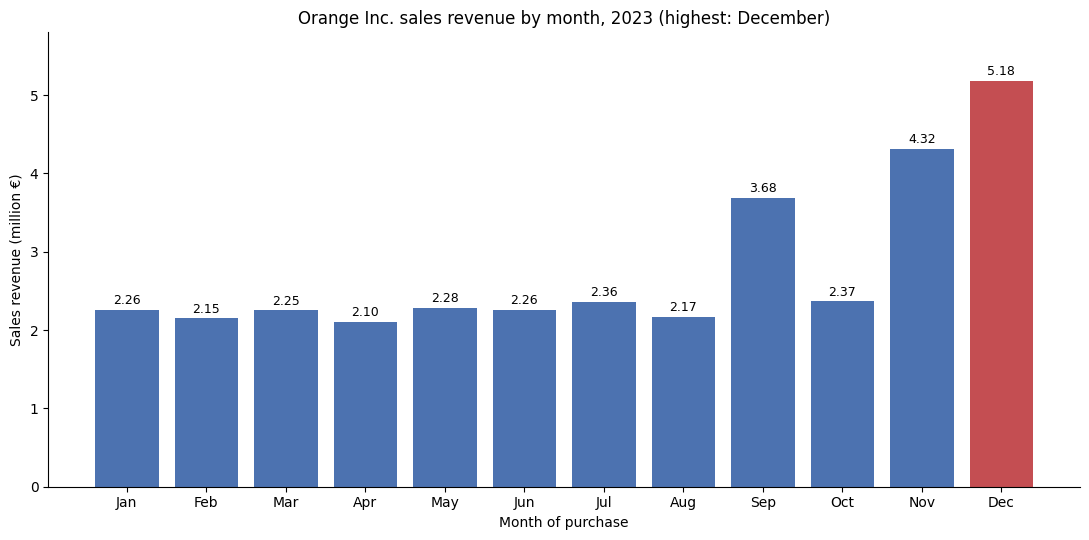

In [12]:
month_labels = [name[:3] for name in month_names]
bar_colors = ["#C44E52" if month == best_month else "#4C72B0" for month in revenue_by_month.index]

fig, ax = plt.subplots(figsize=(11, 5.5))
bars = ax.bar(month_labels, revenue_by_month.values / 1e6, color=bar_colors)
ax.bar_label(bars, fmt="%.2f", fontsize=9, padding=2)
ax.set_title(f"Orange Inc. sales revenue by month, 2023 (highest: {best_month_name})")
ax.set_xlabel("Month of purchase")
ax.set_ylabel("Sales revenue (million €)")
ax.set_ylim(0, revenue_by_month.max() / 1e6 * 1.12)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(IMAGES_DIR / "revenue_by_month.png", dpi=300, bbox_inches="tight")
plt.show()

### Q9b. Pie chart of each product's share of revenue

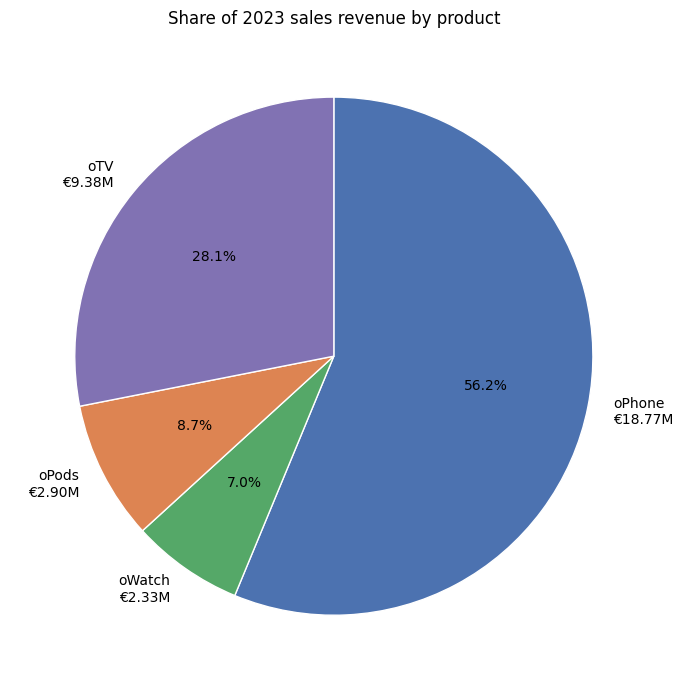

,revenue_share_pct
product,
oPhone,56.24
oWatch,6.98
oPods,8.67
oTV,28.10


In [13]:
revenue_share = revenue_by_product / revenue_by_product.sum() * 100
pie_labels = [f"{product}\n€{revenue / 1e6:.2f}M" for product, revenue in revenue_by_product.items()]

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(revenue_by_product, labels=pie_labels, autopct="%1.1f%%", startangle=90, counterclock=False, colors=["#4C72B0", "#55A868", "#DD8452", "#8172B3"], wedgeprops={"edgecolor": "white"})
ax.set_title("Share of 2023 sales revenue by product")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "revenue_share_by_product.png", dpi=300, bbox_inches="tight")
plt.show()

revenue_share.round(2).to_frame(name="revenue_share_pct")

### Q10. Young oPhone owners

In [14]:
owns_ophone = orange_data_clean["oPhone"] == 1
young_oPhone_owners = orange_data_clean[owns_ophone & is_18_to_25]
print(f"young_oPhone_owners: {len(young_oPhone_owners)} customers")

young_oPhone_owners: 6931 customers


#### Q10a. Most commonly used card type

In [15]:
card_counts = young_oPhone_owners["card"].value_counts()
most_common_card = card_counts.idxmax()
print(f"Most common card type: {most_common_card} ({card_counts.max()} customers)")
card_counts.to_frame(name="customers")

Most common card type: Visa_debit (2975 customers)


,customers
card,
Visa_debit,2975
Mastercard_credit,1497
Visa_credit,1143
Mastercard_debit,736
Other_debit,523
Other_credit,57


#### Q10b. Average number of products (including oPhone)

In [16]:
young_oPhone_average_products = young_oPhone_owners["number_of_products"].mean()
print(f"Average number of products: {young_oPhone_average_products:.3f}")

Average number of products: 2.105


## Managerial questions

### Q11. Own business question

**Question: Which products are bought together, and which product's buyers are the least connected to the rest of the Orange ecosystem?**

For every product X, the attach rate is the share of X buyers who also bought product Y.
The lift divides that attach rate by the share of all customers who bought Y.
A lift above 1 means X buyers are more likely than the average customer to own Y; below 1, less likely.

In [17]:
attach_rows = {}
for base_product in PRODUCT_COLUMNS:
    base_buyers = orange_data_clean[orange_data_clean[base_product] == 1]
    attach_rows[base_product] = base_buyers[PRODUCT_COLUMNS].mean()

attach_rate = pd.DataFrame(attach_rows).T
overall_purchase_rate = orange_data_clean[PRODUCT_COLUMNS].mean()
lift = attach_rate / overall_purchase_rate
for product in PRODUCT_COLUMNS:
    attach_rate.loc[product, product] = float("nan")
    lift.loc[product, product] = float("nan")

print("Share of all customers who bought each product:")
print(overall_purchase_rate.round(3).to_string())
print()
print("Attach rate (row = bought, column = also bought):")
print(attach_rate.round(3).to_string())
print()
print("Lift (row = bought, column = also bought):")
print(lift.round(2).to_string())

Share of all customers who bought each product:
oPhone    0.738
oWatch    0.340
oPods     0.592
oTV       0.184

Attach rate (row = bought, column = also bought):
        oPhone  oWatch  oPods    oTV
oPhone     NaN   0.372  0.630  0.102
oWatch   0.806     NaN  0.552  0.122
oPods    0.785   0.318    NaN  0.106
oTV      0.407   0.225  0.339    NaN

Lift (row = bought, column = also bought):
        oPhone  oWatch  oPods   oTV
oPhone     NaN    1.09   1.06  0.55
oWatch    1.09     NaN   0.93  0.66
oPods     1.06    0.93    NaN  0.57
oTV       0.55    0.66   0.57   NaN


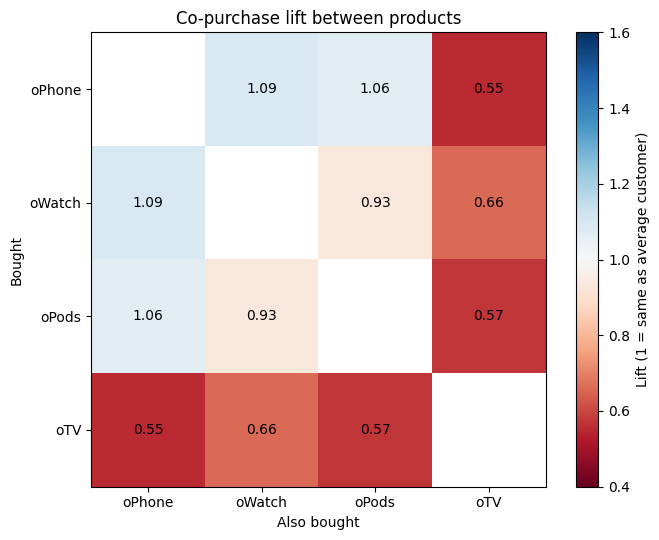

In [18]:
fig, ax = plt.subplots(figsize=(7, 5.5))
image = ax.imshow(lift.values, cmap="RdBu", vmin=0.4, vmax=1.6)
ax.set_xticks(range(len(PRODUCT_COLUMNS)), labels=PRODUCT_COLUMNS)
ax.set_yticks(range(len(PRODUCT_COLUMNS)), labels=PRODUCT_COLUMNS)
ax.set_xlabel("Also bought")
ax.set_ylabel("Bought")
ax.set_title("Co-purchase lift between products")
for row_index, base_product in enumerate(PRODUCT_COLUMNS):
    for column_index, other_product in enumerate(PRODUCT_COLUMNS):
        if base_product != other_product:
            ax.text(column_index, row_index, f"{lift.loc[base_product, other_product]:.2f}", ha="center", va="center")
fig.colorbar(image, ax=ax, label="Lift (1 = same as average customer)")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "co_purchase_lift.png", dpi=300, bbox_inches="tight")
plt.show()

In [19]:
buys_otv = orange_data_clean["oTV"] == 1
otv_buyers = orange_data_clean[buys_otv]
otv_only_buyers = (otv_buyers["number_of_products"] == 1).sum()
otv_buyers_without_ophone = (otv_buyers["oPhone"] == 0).sum()

print(f"oTV buyers: {len(otv_buyers)}")
print(f"oTV buyers who bought nothing else: {otv_only_buyers} ({otv_only_buyers / len(otv_buyers):.1%})")
print(f"oTV buyers without an oPhone: {otv_buyers_without_ophone} ({otv_buyers_without_ophone / len(otv_buyers):.1%})")
print(f"Average products, oTV buyers: {otv_buyers['number_of_products'].mean():.2f}")
print(f"Average products, other customers: {orange_data_clean.loc[~buys_otv, 'number_of_products'].mean():.2f}")

oTV buyers: 3607
oTV buyers who bought nothing else: 1624 (45.0%)
oTV buyers without an oPhone: 2140 (59.3%)
Average products, oTV buyers: 1.97
Average products, other customers: 1.83


**Findings**

- oPhone, oWatch and oPods form a connected core: oWatch buyers own an oPhone in 80.6% of cases against 73.8% of all customers (lift 1.09), and oPods buyers in 78.5% (lift 1.06).
- oTV buyers sit outside this core. Only 40.7% of them also bought an oPhone (lift 0.55), 33.9% oPods (lift 0.57) and 22.5% an oWatch (lift 0.66).
- 45.0% of the 3,607 oTV buyers bought nothing else, and 2,140 of them have no oPhone.

**Business insight:** the oTV brings 28.1% of revenue, but its buyers are the least connected to the rest of the Orange products. They are the clearest cross-selling target: a campaign or bundle that links the oTV with the oPhone and oPods (shared ecosystem features, a discount on a second device) addresses 2,140 customers without an oPhone. As an illustration, converting 10% of them to an oPhone would add about 214 × €1,300 ≈ €278,000 in revenue.
The dataset records one transaction per customer, so a customer may own products bought before 2023; the lift describes what is bought together in the same transaction.

### Q12. Is the segment with the highest total revenue the most valuable one?

**Segment definition:** customers are segmented by loyalty tier (silver, gold, platinum), the segmentation Orange Inc. already uses for marketing.
Age bracket is checked as a second segmentation to see whether the conclusion holds.

**Approach:** for each segment, compare total revenue with measures that are not driven by segment size:
revenue per customer, average number of products and the share of customers who bought more than one product.

In [20]:
def segment_performance(customers: pd.DataFrame, segment_column: str, segment_order: list[str]) -> pd.DataFrame:
    """Summarise customer count, revenue and cross-selling measures per segment."""
    grouped = customers.groupby(segment_column)
    performance = grouped.agg(customers=("user_id", "size"), total_revenue_eur=("sales_revenue", "sum"), revenue_per_customer_eur=("sales_revenue", "mean"), average_products=("number_of_products", "mean"), multiple_product_rate=("purchased_multiple_products", "mean"))
    performance = performance.reindex(segment_order)
    performance["multiple_product_rate"] = performance["multiple_product_rate"] * 100
    performance = performance.rename(columns={"multiple_product_rate": "multiple_product_rate_pct"})
    performance["customer_share_pct"] = performance["customers"] / performance["customers"].sum() * 100
    performance["revenue_share_pct"] = performance["total_revenue_eur"] / performance["total_revenue_eur"].sum() * 100
    return performance.round(2)


tier_performance = segment_performance(orange_data_clean, "tier", TIER_ORDER)
tier_performance

,customers,total_revenue_eur,revenue_per_customer_eur,average_products,multiple_product_rate_pct,customer_share_pct,revenue_share_pct
tier,,,,,,,
silver,12707,20555100,1617.62,1.76,57.83,64.92,61.58
gold,4911,8897550,1811.76,1.98,68.13,25.09,26.66
platinum,1954,3925200,2008.80,2.16,74.67,9.98,11.76


In [21]:
age_performance = segment_performance(orange_data_clean, "age_bracket", AGE_ORDER)
age_performance

,customers,total_revenue_eur,revenue_per_customer_eur,average_products,multiple_product_rate_pct,customer_share_pct,revenue_share_pct
age_bracket,,,,,,,
18-25,8727,14091750,1614.73,1.91,66.85,44.59,42.22
25-34,6940,11505150,1657.80,1.84,61.48,35.46,34.47
34-50,2969,5856600,1972.58,1.74,51.97,15.17,17.55
>50,936,1924350,2055.93,1.79,54.49,4.78,5.77


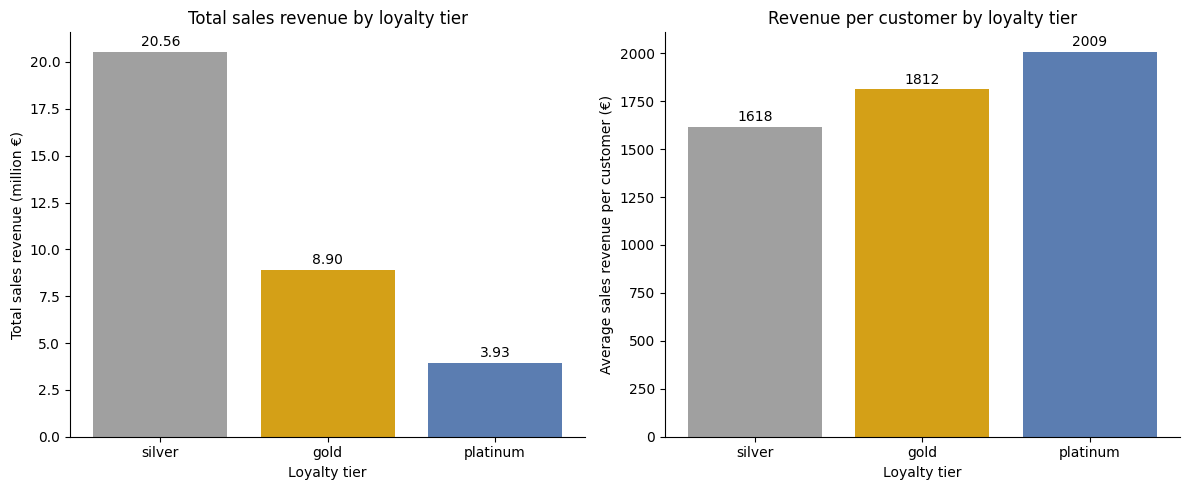

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
tier_colors = ["#A0A0A0", "#D4A017", "#5B7DB1"]

total_bars = axes[0].bar(TIER_ORDER, tier_performance["total_revenue_eur"] / 1e6, color=tier_colors)
axes[0].bar_label(total_bars, fmt="%.2f", padding=2)
axes[0].set_title("Total sales revenue by loyalty tier")
axes[0].set_xlabel("Loyalty tier")
axes[0].set_ylabel("Total sales revenue (million €)")

per_customer_bars = axes[1].bar(TIER_ORDER, tier_performance["revenue_per_customer_eur"], color=tier_colors)
axes[1].bar_label(per_customer_bars, fmt="%.0f", padding=2)
axes[1].set_title("Revenue per customer by loyalty tier")
axes[1].set_xlabel("Loyalty tier")
axes[1].set_ylabel("Average sales revenue per customer (€)")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(IMAGES_DIR / "segment_value_by_tier.png", dpi=300, bbox_inches="tight")
plt.show()

**Conclusion: the claim is not supported.**

- Silver generates the highest total revenue (€20.56M, 61.6% of the total), but only because it holds 64.9% of the customers. Its revenue share is below its customer share.
- Per customer, the ranking is reversed: platinum customers spend €2,009 on average against €1,812 for gold and €1,618 for silver (+24% for platinum over silver).
- Platinum customers also buy more products (2.16 against 1.76 for silver) and 74.7% of them bought more than one product, against 68.1% for gold and 57.8% for silver.
- Segmenting by age gives the same pattern: 18-25 has the highest total revenue (42.2%) but the lowest revenue per customer (€1,615), while customers over 50 spend €2,056 each.

Total revenue measures the size of a segment, not the value of its customers. Silver matters for volume, but platinum is the most valuable segment per customer, and moving silver customers up to gold or platinum behaviour is the larger lever.

**Additional information needed:** purchase history over several years per customer (repeat purchases and retention). With a single transaction per customer the data shows one year's spend, not customer lifetime value; retention and repeat-purchase rates per tier, together with product margins and the cost of the loyalty programme, would show which segment is most profitable over time.

## Conclusions

| Question | Answer |
|---|---|
| Q2 | 428 rows with missing values removed; 19,572 observations left |
| Q3 | 12,154 customers purchased multiple products |
| Q4 | 1,916 female customers aged 18-25 paid with a Visa or Mastercard credit card |
| Q5 | 3,733 customers, 19.07% of `orange_data_clean` |
| Q6 | 364 customers purchased all four products |
| Q7 | Average products: silver 1.757, gold 1.982, platinum 2.162 |
| Q8a | Total sales revenue €33,377,850 |
| Q8b | December has the highest revenue (€5,180,000) |
| Q8c | oPhone €18,773,300, oTV €9,378,200, oPods €2,895,000, oWatch €2,331,350 |
| Q10a | Visa_debit is the most common card (2,975 of 6,931 young oPhone owners) |
| Q10b | Young oPhone owners bought 2.105 products on average |

Revenue is flat at about €2.1-2.4M per month and rises in September, November and December. The oPhone brings 56.2% of revenue.
oTV buyers are the least connected to the other products (Q11), and the largest segment by total revenue is not the most valuable per customer (Q12).